# M09-2 | How ORT Executes QDQ ONNX: Five Graph Optimization Levels and QDQ Node Fusion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m09_onnx_runtime/02_ort_qdq_fusion.ipynb)

The QDQ ONNX of M09-1 contains no int8 kernel, only `QuantizeLinear` / `DequantizeLinear` wrapped around an fp32 `Conv`. What swaps in int8 kernels is ONNX Runtime (ORT): when creating an `InferenceSession`, ORT rewrites the graph according to the **graph optimization level**, then hands each node to an Execution Provider (EP) to run.

```text
QDQ ONNX (M09-1)
  → ort.InferenceSession(…, sess_options, providers)   pick EPs, rewrite the graph per the optimization level
  → session.run                                         run the rewritten graph
```

- **A.** Which EPs this ORT build has.
- **B.** What each of the five levels rewrites TinyConvNet's QDQ ONNX into.

Which rewrites each level registers in the ORT source, and how each kind of op is handled, are summarized in the [M09 overview](00_overview.ipynb).

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m09_onnx_runtime")

In [2]:
import tempfile
from pathlib import Path

import numpy as np
import onnx
import onnxruntime as ort
import torch
from onnx import numpy_helper

from common.pt2e import quiet  # must be imported before onnx/torchao
from common.data import trained_tiny_net
from common.env import env_summary
from common.models import example_inputs
from common.onnx_utils import LEVELS, onnx_op_counts, optimized_model, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f" | onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


The input is M09-1's QDQ ONNX: PT2E (`xnnpack_qdq`) produces the Q/DQ graph, then `torch.onnx.export(Q/DQ graph, x, dynamo=True)` (`to_onnx`) exports it.

In [3]:
x = example_inputs()
onnx_model = to_onnx(xnnpack_qdq(trained_tiny_net(), x), x)

## A. Which EPs This ORT Build Has

In [4]:
print("ort.get_available_providers():", ort.get_available_providers())

ort.get_available_providers()： ['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']


When creating sessions this chapter always specifies `providers=["CPUExecutionProvider"]`: every ORT build has this EP, and its kernels are ORT's own MLAS, a different implementation from M08's XNNPACK. What an EP is, and how the order of the list decides which one is used, is in the M07 overview, "One Library, Several Frameworks".

## B. The Five Graph Optimization Levels

ORT 1.30 has five levels, each including the previous one (details in the M09 overview):

| Level | What this level adds |
|---|---|
| `ORT_DISABLE_ALL` | Runs only the required steps, e.g. making each DQ feed only one op |
| `ORT_ENABLE_BASIC` | EP-independent simplification; bias quantized to int32 |
| `ORT_ENABLE_EXTENDED` | QDQ node fusion: `DQ → op → Q` becomes an int8 op |
| `ORT_ENABLE_LAYOUT` | CPU layout: int8 Conv becomes NHWC |
| `ORT_ENABLE_ALL` | fp16 constants to fp32; the default of `InferenceSession` |

How do we see the graph ORT rewrote? Pass `SessionOptions.optimized_model_filepath` when creating the session, and ORT saves the rewritten graph as an `.onnx`:

In [5]:
so = ort.SessionOptions()
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
with tempfile.TemporaryDirectory() as d:
    so.optimized_model_filepath = str(Path(d) / "optimized.onnx")
    ort.InferenceSession(onnx_model.SerializeToString(), so, providers=["CPUExecutionProvider"])
    extended = onnx.load(so.optimized_model_filepath)
print("After EXTENDED rewrite:", dict(onnx_op_counts(extended)))

EXTENDED 改寫後： {'QuantizeLinear': 2, 'QLinearConv': 4, 'MaxPool': 2, 'com.microsoft.QLinearAdd': 1, 'DequantizeLinear': 2, 'ReduceMean': 1, 'Reshape': 1, 'com.microsoft.QGemm': 1}


ORT makes the same rewrites whenever it creates a session, it just does not save them. This project wraps these lines as `optimized_model(onnx_model, level)` (`common/onnx_utils.py`). Run it once per level and compare the op counts:

In [6]:
graphs = {"Exported QDQ ONNX": onnx_model} | {lv: optimized_model(onnx_model, lv) for lv in LEVELS}
counts = {name: onnx_op_counts(g) for name, g in graphs.items()}
ops = sorted(set().union(*counts.values()), key=lambda o: (-counts["Exported QDQ ONNX"].get(o, 0), o))
table([[op] + [counts[name].get(op, "") for name in graphs] for op in ops],
      ["op"] + [name.replace("ORT_", "") for name in graphs])

op,匯出的 QDQ ONNX,DISABLE_ALL,ENABLE_BASIC,ENABLE_EXTENDED,ENABLE_LAYOUT,ENABLE_ALL
DequantizeLinear,16,17,22,2,2,2
QuantizeLinear,11,11,11,2,2,2
Conv,4,4,4,,,
Relu,4,4,4,,,
MaxPool,2,2,2,2,,
Add,1,1,1,,,
Gemm,1,1,1,,,
ReduceMean,1,1,1,1,1,1
Reshape,1,1,1,1,1,1
QLinearConv,,,,4,,


Now one level at a time.

### `ORT_DISABLE_ALL`: One More DequantizeLinear

"Disabling optimization" also changes the graph. Take the merged DequantizeLinear from section A of M09-1, and first look at the exported QDQ ONNX:

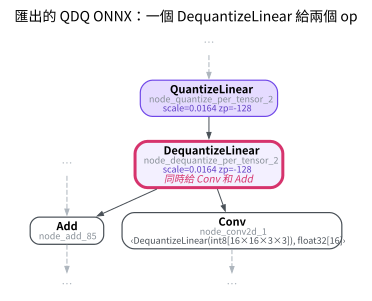

In [7]:
dis = graphs["ORT_DISABLE_ALL"]
dup = next(n.name for n in dis.graph.node if n.name.endswith("/duplicated"))  # DQ copied by ORT
shared = dup.removesuffix("/duplicated")                                    # the originally shared DQ
draw_onnx(onnx_model, focus=shared, hops=1, highlight=[shared], notes={shared: "Feeds both Conv and Add"},
          title="Exported QDQ ONNX: one DequantizeLinear feeding two ops")

The same region after `ORT_DISABLE_ALL` rewrites it:

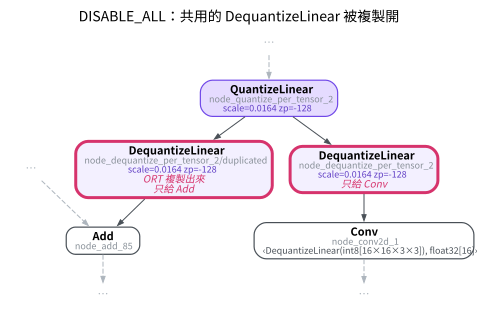

In [8]:
draw_onnx(dis, focus=[shared, dup], hops=1, highlight=[shared, dup],
          notes={shared: "Feeds Conv only", dup: "Copied by ORT\nFeeds Add only"},
          title="DISABLE_ALL: the shared DequantizeLinear is duplicated")

In [9]:
def users(model, name):
    out = next(n.output[0] for n in model.graph.node if n.name == name)
    return sorted(n.op_type for n in model.graph.node if out in n.input)


print(f"Exported QDQ ONNX: {shared} → {users(onnx_model, shared)}")
print(f"DISABLE_ALL: {shared} → {users(dis, shared)}; {dup} → {users(dis, dup)}")
assert users(onnx_model, shared) == ["Add", "Conv"] and users(dis, shared) == ["Conv"] and users(dis, dup) == ["Add"]

匯出的 QDQ ONNX：node_dequantize_per_tensor_2 → ['Add', 'Conv']
DISABLE_ALL：node_dequantize_per_tensor_2 → ['Conv']；node_dequantize_per_tensor_2/duplicated → ['Add']


The one DequantizeLinear that fed both the `Add` and the next `Conv` now has a separate copy for the `Add` (`…/duplicated`). This is ORT's `EnsureUniqueDQForNodeUnit`: the later fusions rewrite in units of "DQ → op → Q" (node units), and each unit needs its own DQ. The source lists it as a required step, so even DISABLE_ALL runs it.

### `ORT_ENABLE_BASIC`: The Bias Becomes int32

There are a few more DequantizeLinear. Look at the first conv:

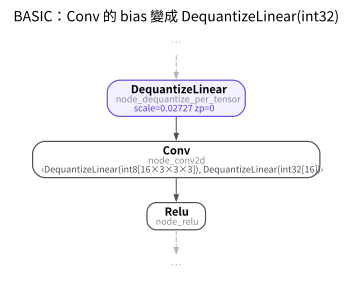

In [10]:
basic = graphs["ORT_ENABLE_BASIC"]
draw_onnx(basic, focus="node_conv2d", hops=1, title="BASIC: the Conv bias becomes DequantizeLinear(int32)")

The Conv's third input used to be a float32 bias; now it is `DequantizeLinear(int32[…])`: ORT quantized the fp32 bias to int32 (`WeightBiasQuantization` in the source). Check whether the int32 bias is $\operatorname{round}(b / (s_x \cdot s_w))$, where $s_x$ is the scale of the Conv input and $s_w$ is the weight's per-channel scale:

In [11]:
def consts(model):
    return {i.name: numpy_helper.to_array(i) for i in model.graph.initializer}


def conv_node(model):
    return next(n for n in model.graph.node if n.name == "node_conv2d")


src, by_out = consts(onnx_model), {n.output[0]: n for n in onnx_model.graph.node}
conv = conv_node(onnx_model)
s_x = float(src[by_out[conv.input[0]].input[1]])            # scale of the input DequantizeLinear
s_w = src[by_out[conv.input[1]].input[1]]                   # per-channel scale of the weight DequantizeLinear
b_fp32 = src[conv.input[2]]
b_by_out = {n.output[0]: n for n in basic.graph.node}
b_int32 = consts(basic)[b_by_out[conv_node(basic).input[2]].input[0]]
same = np.array_equal(b_int32, np.round(b_fp32 / (s_x * s_w)).astype(np.int32))
print(f"int32 bias == round(fp32 bias / (s_x · s_w)): {same}")
assert b_int32.dtype == np.int32 and same

int32 bias == round(fp32 bias / (s_x · s_w))：True


As with M08's XNNPACK, the scale is $s_x \cdot s_w$. The difference is the timing: XNNPACK does it when exporting the `.pte`, ORT does it when creating the session.

### `ORT_ENABLE_EXTENDED`: QDQ Node Fusion

int8 kernels appear only from this level on. The first conv unit:

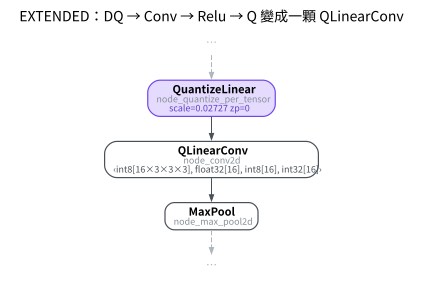

In [12]:
ext = graphs["ORT_ENABLE_EXTENDED"]
draw_onnx(ext, focus="node_conv2d", hops=1, title="EXTENDED: DQ → Conv → Relu → Q becomes one QLinearConv")

The original "DequantizeLinear → Conv → Relu → QuantizeLinear" becomes a single `QLinearConv`: its inputs and outputs are int8, and the `‹…›` lists, in order, the int8 weight, the weight's scale and zero point, and the int32 bias (done at BASIC). The scale and zero point of the input and output are also its parameters (scalars, not printed).

Where did the Relu go? Look at the zero point of the QuantizeLinear after the Relu:

In [13]:
nodes = list(onnx_model.graph.node)
relu = next(n for n in nodes if n.op_type == "Relu")
q = next(n for n in nodes if n.op_type == "QuantizeLinear" and n.input[0] == relu.output[0])
zp = src[q.input[2]]
print(f"QuantizeLinear after Relu: zero point = {int(zp)}, lower bound of {zp.dtype} = {np.iinfo(zp.dtype).min}")
assert int(zp) == np.iinfo(zp.dtype).min

Relu 後面的 QuantizeLinear：zero point = -128，int8 的下限 = -128


The zero point is exactly int8's lower bound: real 0 maps to -128, and negative values would be clamped to -128 inside QuantizeLinear anyway. After quantization the Relu changes no value, so ORT removes it (`ReluQuantFusion` in the source, applied only when the zero point equals the lower bound). The zero point is the lower bound because the minimum the observer saw at the relu output is 0.

Not every unit can be swapped. Look near `ReduceMean` (the op `AdaptiveAvgPool2d(1)` exports to):

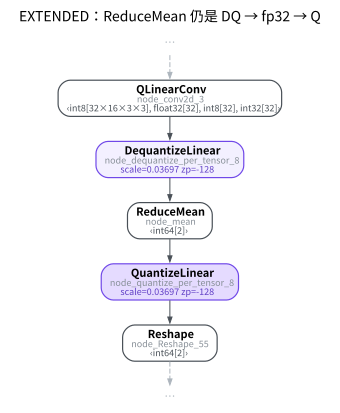

In [14]:
draw_onnx(ext, focus=lambda n: n.op_type == "ReduceMean", hops=2, title="EXTENDED: ReduceMean is still DQ → fp32 → Q")

In [15]:
dq_out = {n.output[0] for n in ext.graph.node if n.op_type == "DequantizeLinear"}
fp32_ops = sorted({n.op_type for n in ext.graph.node if n.op_type != "QuantizeLinear" and set(n.input) & dq_out})
print("Ops that still consume DequantizeLinear output after EXTENDED:", fp32_ops)
assert fp32_ops == ["ReduceMean"]

EXTENDED 之後仍吃 DequantizeLinear 輸出的 op： ['ReduceMean']


- `ReduceMean` is not on the QDQ fusion list, so it stays "DQ → fp32 compute → Q", with one int8 ↔ fp32 conversion before and one after.
- The `Reshape` below it, like the earlier `MaxPool`, has the surrounding Q/DQ removed and runs directly on int8: an op that only moves data or takes a maximum gives the same result on int8.
- One QuantizeLinear remains at the graph input and one DequantizeLinear at the output; those are the true fp32 ↔ int8 conversions.

Which group the other ops belong to is summarized in the M09 overview, "The Three Groups of QDQ Node Fusion".

### `ORT_ENABLE_LAYOUT`: int8 Conv Becomes NHWC

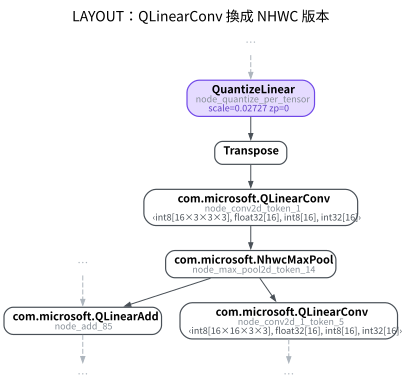

In [16]:
layout = graphs["ORT_ENABLE_LAYOUT"]
first_conv = next(n.name for n in layout.graph.node if n.op_type == "QLinearConv")  # the NHWC version renames the node
draw_onnx(layout, focus=first_conv, hops=2, title="LAYOUT: QLinearConv becomes the NHWC version")

`NhwcTransformer` replaces `QLinearConv` with the NHWC version of `com.microsoft.QLinearConv` and inserts `Transpose` before and after the int8 segment; the `MaxPool` in between also becomes `com.microsoft.NhwcMaxPool`. `com.microsoft.*` ops are defined by ORT itself, are not in the ONNX standard, and only ORT understands them.

Why switch to NHWC? ORT CPU's int8 conv kernel (`QLinearConv`) computes only in NHWC. Every run of an NCHW `QLinearConv` first converts each image to NHWC inside the kernel, then converts back to NCHW after computing (from reading ORT v1.30.0's `qlinearconv.cc`). So no Transpose is visible in the EXTENDED graph, yet every `QLinearConv` transposes twice.

`NhwcTransformer` lifts the transposes into the graph, adjacent Transposes that cancel each other are then removed, and the whole int8 segment transposes only once at each end; `MaxPool` is also switched to the NHWC version so the layout is not interrupted midway. `QLinearAdd` is element-wise and independent of layout, so it stays in the middle. Count the Transposes in the graphs of the two levels:

In [17]:
def n_ops(model, op_type):
    return sum(n.op_type == op_type for n in model.graph.node)


for name, g in [("EXTENDED", ext), ("LAYOUT", layout)]:
    print(f"{name}: {n_ops(g, 'QLinearConv')} QLinearConv, {n_ops(g, 'Transpose')} Transpose in the graph")
assert n_ops(ext, "Transpose") == 0 and n_ops(layout, "Transpose") == 2 and n_ops(layout, "QLinearConv") == 4

EXTENDED：QLinearConv 4 顆，圖上的 Transpose 0 顆
LAYOUT：QLinearConv 4 顆，圖上的 Transpose 2 顆


### `ORT_ENABLE_ALL`

In [18]:
same = [n.op_type for n in graphs["ORT_ENABLE_ALL"].graph.node] == [n.op_type for n in graphs["ORT_ENABLE_LAYOUT"].graph.node]
print("ALL and LAYOUT produce the same graph:", same)
assert same

ALL 與 LAYOUT 改寫出的圖相同： True


ALL adds only "fp16 constants to fp32" over LAYOUT, and this model has no fp16 constants, so the two are the same.

## Summary

- QDQ ONNX is backend-neutral: the file contains only the standard `QuantizeLinear` / `DequantizeLinear`, and whether they become int8 kernels is decided at run time by the EP and the optimization level.
- DISABLE_ALL also duplicates a shared DQ; BASIC quantizes the bias to int32; from EXTENDED on, Conv is int8 and Relu is folded into Q; LAYOUT switches to NHWC, lifting the kernel-internal transposes to the two ends of the int8 segment; ALL adds only fp16 handling.
- Ops not on the fusion list (here `ReduceMean`) stay in fp32.
- The same `.onnx` is rewritten differently on x86 (M09 overview, "Platform-Dependent").